# TP N° 2 - Inteligencia Artificial
## Procesamiento de series temporales de baterías CALCE (CS2_35)

Transformación de mediciones por segundo a ciclos de carga/descarga, extrayendo atributos de entrada (X) y objetivos (Y: SOH y RUL) para el entrenamiento de una RNA.

**Pipeline:**
1. Cargar y ordenar cronológicamente los archivos Excel del Arbin BT2000.
2. Detectar transiciones: Carga (I > 0) → Reposo (I ≈ 0) → Descarga (I < 0).
3. Extraer atributos por ciclo (X): `Voltaje_medio_descarga`, `Tiempo_fase_CV`, `Resistencia_interna`.
4. Calcular targets (Y): `SOH (%)` y `RUL = k_EOL - k`.
5. Limpiar ciclos de solo reposo y suavizar saltos abruptos.
6. Normalizar X con MinMaxScaler y exportar único archivo tabular.

In [ ]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.preprocessing import MinMaxScaler
from google.colab import drive

drive.mount('/content/drive')

# Rutas de entrada, tabla intermedia y archivo final normalizado
PATH_DATOS_RUDOS = '/content/drive/MyDrive/IA 2C 2026 G12/TP 2/Datos/Raw_data/'
PATH_CSV_INTERMEDIO = '/content/drive/MyDrive/IA 2C 2026 G12/TP 2/Datos/datos Procesados/dataset_CS2_35_ciclos_intermedio.csv'
PATH_CSV_FINAL = '/content/drive/MyDrive/IA 2C 2026 G12/TP 2/Datos/datos Procesados/dataset_CS2_35_ciclos.csv'

# Parametros fisicos y de tolerancia electroquimica
UMBRAL_CORRIENTE = 0.01        # Tolerancia para detectar I ~ 0 A (reposo)
VOLTAJE_CORTE_DESCARGA = 2.7  # Limite inferior seguro de descarga [V]
VOLTAJE_FASE_CV = 4.17         # Umbral para detectar la fase CV (setpoint 4.2V, medicion real ~4.18V)
CAPACIDAD_NOMINAL = 1.1        # Capacidad nominal de fabrica de la celda CS2 [Ah]
UMBRAL_EOL_SOH = 80.0          # Fin de Vida util (End of Life) [%]

print("Entorno configurado correctamente.")

Mounted at /content/drive
Entorno configurado correctamente.


---
## 1. Deteccion de transiciones

Clasificamos cada segundo de medicion segun el signo y magnitud de la corriente:
- **Carga**: I > umbral (la celda recibe energia)
- **Descarga**: I < -umbral (la celda entrega energia)
- **Neutralidad/Reposo**: |I| <= umbral (transicion o reposo)

In [ ]:
def clasificar_estado_instante(corriente, epsilon=UMBRAL_CORRIENTE):
    """Clasifica un instante en Carga, Descarga o Neutralidad segun la corriente."""
    if corriente > epsilon:
        return 'Carga'
    elif corriente < -epsilon:
        return 'Descarga'
    else:
        return 'Neutralidad'


def cargar_y_etiquetar_archivo(filepath):
    """
    Carga una planilla Excel del Arbin BT2000, normaliza los nombres de columnas
    y clasifica segundo a segundo el estado operativo de la celda.
    """
    xls = pd.ExcelFile(filepath)
    hojas_validas = [s for s in xls.sheet_names if 'Channel' in s or 'Data' in s]

    dfs = [pd.read_excel(xls, sheet_name=s) for s in hojas_validas]
    df = pd.concat(dfs, ignore_index=True)

    col_map = {
        'Test_Time(s)': 'Tiempo_s',
        'Current(A)': 'Corriente_A',
        'Voltage(V)': 'Voltaje_V',
        'Charge_Capacity(Ah)': 'Cap_Carga_Ah',
        'Discharge_Capacity(Ah)': 'Cap_Descarga_Ah',
        'Step_Index': 'Paso_Index',
        'Cycle_Index': 'Ciclo_Arbin',
    }
    df = df.rename(columns={k: v for k, v in col_map.items() if k in df.columns})

    df['Estado'] = df['Corriente_A'].apply(clasificar_estado_instante)
    return df

print("Funciones de segmentacion por segundo definidas.")

Funciones de segmentacion por segundo definidas.


---
## 2. Deteccion de ciclos y extraccion de atributos (X) + SOH (Y)

Cada ciclo valido sigue el patron **Carga -> Reposo -> Descarga**, y la descarga debe alcanzar el voltaje de corte (ciclo completo).

**Atributos de entrada (X):**
- `Voltaje_Medio_Descarga_V`: voltaje promedio durante toda la descarga
- `Tiempo_Fase_CV_s`: duracion en segundos bajo voltaje constante (~4.17-4.20 V)
- `Resistencia_Interna_Ohm`: dV / I al cortar la descarga (salto ohmico)

**Target parcial (Y):**
- `SOH_%` = (Capacidad descargada / 1.1 Ah) x 100

> El RUL se calcula despues de consolidar todos los archivos, con numeracion de ciclo global.

In [ ]:
def extraer_ciclos(df_raw):
    """
    Agrupa los registros segundo a segundo en ciclos discretos.
    Extrae los atributos de entrada (X) y calcula el SOH (Y) por ciclo.
    El RUL se calcula globalmente despues de consolidar todos los archivos.
    """
    df_raw['Cambio_Estado'] = (df_raw['Estado'] != df_raw['Estado'].shift(1)).cumsum()
    subfases = [grupo for _, grupo in df_raw.groupby('Cambio_Estado')]

    ciclos_extraidos = []
    i = 0

    while i < len(subfases) - 2:
        fase_carga = subfases[i]
        fase_descarga = subfases[i + 2]

        es_carga = fase_carga['Estado'].iloc[0] == 'Carga'
        es_descarga = fase_descarga['Estado'].iloc[0] == 'Descarga'

        if es_carga and es_descarga:
            v_min_descarga = fase_descarga['Voltaje_V'].min()
            if v_min_descarga <= (VOLTAJE_CORTE_DESCARGA):

                # Tiempo bajo voltaje constante (CV) durante la carga
                fase_cv = fase_carga[fase_carga['Voltaje_V'] >= VOLTAJE_FASE_CV]
                if len(fase_cv) > 0:
                    tiempo_fase_cv = fase_cv['Tiempo_s'].max() - fase_cv['Tiempo_s'].min()
                else:
                    tiempo_fase_cv = 0.0

                voltaje_medio_descarga = fase_descarga['Voltaje_V'].mean()

                # Resistencia interna: dV / I al cortar la descarga
                v_final_descarga = fase_descarga['Voltaje_V'].iloc[-1]
                i_final_descarga = abs(fase_descarga['Corriente_A'].iloc[-1])

                if (i + 3) < len(subfases) and subfases[i + 3]['Estado'].iloc[0] == 'Neutralidad':
                    v_reposo_post = subfases[i + 3]['Voltaje_V'].iloc[0]
                    delta_v = abs(v_reposo_post - v_final_descarga)
                    resistencia_interna = delta_v / i_final_descarga if i_final_descarga > 0 else np.nan
                else:
                    resistencia_interna = np.nan

                # Capacidad descargada: contador del Arbin si existe, si no, integracion numerica
                if 'Cap_Descarga_Ah' in fase_descarga.columns:
                    capacidad_descargada = fase_descarga['Cap_Descarga_Ah'].max() - fase_descarga['Cap_Descarga_Ah'].min()
                else:
                    capacidad_descargada = np.trapz(abs(fase_descarga['Corriente_A']), fase_descarga['Tiempo_s']) / 3600.0

                soh = (capacidad_descargada / CAPACIDAD_NOMINAL) * 100.0

                ciclos_extraidos.append({
                    'Voltaje_Medio_Descarga_V': voltaje_medio_descarga,
                    'Tiempo_Fase_CV_s': tiempo_fase_cv,
                    'Resistencia_Interna_Ohm': resistencia_interna,
                    'Capacidad_Descargada_Ah': capacidad_descargada,
                    'SOH_%': soh,
                })
                i += 3
                continue
        i += 1

    df_ciclos = pd.DataFrame(ciclos_extraidos)
    df_ciclos['Resistencia_Interna_Ohm'] = df_ciclos['Resistencia_Interna_Ohm'].interpolate().bfill()

    return df_ciclos

print("Algoritmo de extraccion por ciclo configurado.")

Algoritmo de extraccion por ciclo configurado.


---
## 3. Pipeline: carga, agregacion global y exportacion (valores crudos)

1. Busca todos los `.xlsx` (recursivo en subcarpetas) y los **ordena cronologicamente** por fecha.
2. Procesa cada archivo en orden temporal.
3. Consolida todos los ciclos con numeracion global: `k = 1, 2, ..., N`.
4. Calcula `RUL = k_EOL - k` donde `k_EOL` es el ciclo global donde `SOH <= 80%`.
5. Exporta la tabla intermedia (sin normalizar) a `PATH_CSV_INTERMEDIO`.

In [17]:
# --- Ordenamiento cronologico ---
def extraer_fecha_archivo(filepath):
    """Extrae la fecha del nombre de archivo y devuelve un datetime para ordenar."""
    nombre = os.path.basename(filepath).replace('.xlsx', '')
    match = re.search(r'CS2_35_(\d+)_(\d+)_(\d+)', nombre)
    if match:
        mes, dia, anio_corto = int(match.group(1)), int(match.group(2)), int(match.group(3))
        anio = 2000 + anio_corto
        return datetime(anio, mes, dia)
    return datetime.max

# --- Buscar y ordenar archivos ---
archivos_excel = glob.glob(os.path.join(PATH_DATOS_RUDOS, '**', '*.xlsx'), recursive=True)
archivos_excel.sort(key=extraer_fecha_archivo)

# --- Procesar cada archivo en orden cronologico ---
if not archivos_excel:
    print(f"No se encontraron archivos Excel en {PATH_DATOS_RUDOS}. Verifique la ruta.")
else:
    lista_df_ciclos = []

    for archivo in archivos_excel:
        print(f"Procesando: {os.path.basename(archivo)} ...")
        df_raw = cargar_y_etiquetar_archivo(archivo)
        df_ciclos = extraer_ciclos(df_raw)
        df_ciclos['Bateria_Origen'] = os.path.basename(archivo).replace('.xlsx', '')
        lista_df_ciclos.append(df_ciclos)

    dataset_final = pd.concat(lista_df_ciclos, ignore_index=True)
    dataset_final['Ciclo_k'] = np.arange(1, len(dataset_final) + 1)

    ciclos_eol = dataset_final[dataset_final['SOH_%'] <= UMBRAL_EOL_SOH]['Ciclo_k']
    k_eol = ciclos_eol.iloc[0] if len(ciclos_eol) > 0 else dataset_final['Ciclo_k'].max()
    dataset_final['RUL_Ciclos'] = (k_eol - dataset_final['Ciclo_k']).clip(lower=0)

    os.makedirs(os.path.dirname(PATH_CSV_INTERMEDIO), exist_ok=True)
    dataset_final.to_csv(PATH_CSV_INTERMEDIO, index=False)

    print(f"\nProceso completado con exito")
    print(f"Total de ciclos extraidos: {len(dataset_final)}")
    print(f"Tabla intermedia guardada en: {PATH_CSV_INTERMEDIO}")
    print(f"k_EOL (ciclo donde SOH <= {UMBRAL_EOL_SOH}%): {k_eol}")
    print("\nPrimeras 5 filas de la tabla cruda:")
    display(dataset_final.head())

No se encontraron archivos Excel en /content/drive/MyDrive/IA 2C 2026 G12/TP 2/Datos/Raw_data/. Verifique la ruta.


---
## 3.1. Limpieza: eliminacion de ciclos de solo reposo

Algunos ciclos extraidos pueden corresponder a periodos donde la celda estuvo en reposo sin carga ni descarga reales. Se reconocen por:
- `Capacidad_Descargada_Ah ~ 0` (no hubo descarga)
- `Tiempo_Fase_CV_s = 0` (no hubo fase de carga)

Se eliminan, se renumera `Ciclo_k` secuencialmente y se recalcula el RUL.

In [ ]:
mascara_reposo = (dataset_final['Capacidad_Descargada_Ah'] < 1e-6) & (dataset_final['Tiempo_Fase_CV_s'] == 0)

ciclos_eliminados = mascara_reposo.sum()
print(f"Ciclos antes del filtro: {len(dataset_final)}")
print(f"Ciclos de solo reposo eliminados: {ciclos_eliminados}")

dataset_final = dataset_final[~mascara_reposo].reset_index(drop=True)
dataset_final['Ciclo_k'] = np.arange(1, len(dataset_final) + 1)

ciclos_eol = dataset_final[dataset_final['SOH_%'] <= UMBRAL_EOL_SOH]['Ciclo_k']
k_eol = ciclos_eol.iloc[0] if len(ciclos_eol) > 0 else dataset_final['Ciclo_k'].max()
dataset_final['RUL_Ciclos'] = (k_eol - dataset_final['Ciclo_k']).clip(lower=0)

dataset_final.to_csv(PATH_CSV_INTERMEDIO, index=False)

print(f"Ciclos despues del filtro: {len(dataset_final)}")
print(f"k_EOL actualizado: {k_eol}")
print(f"Tabla intermedia actualizada en: {PATH_CSV_INTERMEDIO}")
print("\nPrimeras 5 filas de la tabla cruda limpia:")
display(dataset_final.head())

NameError: name 'dataset_final' is not defined

---
## 3.1.1. Deteccion y suavizado de saltos abruptos

El SOH puede presentar saltos abruptos por artefactos de medicion (reinicio del contador del Arbin entre archivos, ruido, descargas parciales). Estrategia:
1. Acotar SOH al rango fisico [0%, 100%].
2. Suavizar SOH y resistencia interna con mediana movil (ventana de 5 ciclos).
3. Recalcular RUL sobre el SOH suavizado.

In [15]:
# --- 1. Acotar SOH al rango fisico [0%, 100%] ---
soh_antes = dataset_final['SOH_%'].copy()
dataset_final['SOH_%'] = dataset_final['SOH_%'].clip(upper=100.0, lower=0.0)
saturados = (soh_antes > 100).sum() + (soh_antes < 0).sum()
print(f"SOH saturado al rango [0, 100]%: {saturados} valores corregidos")

# --- 2. Detectar saltos abruptos ---
UMBRAL_SALTO_SOH = 3.0
delta_soh = dataset_final['SOH_%'].diff().abs()
mascara_salto = delta_soh > UMBRAL_SALTO_SOH
print(f"Saltos abruptos detectados (|dSOH| > {UMBRAL_SALTO_SOH}%): {mascara_salto.sum()}")

# --- 3. Suavizado por mediana movil (ventana de 5 ciclos) ---
VENTANA_MEDIANA = 5
dataset_final['SOH_%'] = dataset_final['SOH_%'].rolling(
    window=VENTANA_MEDIANA, center=True, min_periods=1
).median()

dataset_final['Resistencia_Interna_Ohm'] = dataset_final['Resistencia_Interna_Ohm'].rolling(
    window=VENTANA_MEDIANA, center=True, min_periods=1
).median()

# --- 4. Recalcular RUL sobre el SOH suavizado ---
ciclos_eol = dataset_final[dataset_final['SOH_%'] <= UMBRAL_EOL_SOH]['Ciclo_k']
k_eol = ciclos_eol.iloc[0] if len(ciclos_eol) > 0 else dataset_final['Ciclo_k'].max()
dataset_final['RUL_Ciclos'] = (k_eol - dataset_final['Ciclo_k']).clip(lower=0)

dataset_final.to_csv(PATH_CSV_INTERMEDIO, index=False)

print(f"\nSuavizado aplicado (mediana movil, ventana={VENTANA_MEDIANA})")
print(f"Total de ciclos: {len(dataset_final)}")
print(f"k_EOL actualizado: {k_eol}")
print(f"Tabla intermedia actualizada en: {PATH_CSV_INTERMEDIO}")

# --- 5. Comparacion visual antes vs despues ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(soh_antes.values, color='tab:red', alpha=0.5, label='SOH original')
axes[0].plot(dataset_final['SOH_%'].values, color='tab:blue', label='SOH suavizado')
axes[0].axhline(y=UMBRAL_EOL_SOH, color='black', linestyle='--', alpha=0.5, label=f'EOL ({UMBRAL_EOL_SOH}%)')
axes[0].set_xlabel('Ciclo k')
axes[0].set_ylabel('SOH (%)')
axes[0].set_title('SOH: original vs suavizado')
axes[0].legend()

axes[1].plot(dataset_final['Ciclo_k'], dataset_final['SOH_%'], color='tab:blue')
axes[1].axhline(y=UMBRAL_EOL_SOH, color='r', linestyle='--', label=f'EOL ({UMBRAL_EOL_SOH}%)')
axes[1].set_xlabel('Ciclo k')
axes[1].set_ylabel('SOH (%)')
axes[1].set_title('SOH suavizado final')
axes[1].legend()

plt.tight_layout()
plt.show()

NameError: name 'dataset_final' is not defined

---
## 3.2. Normalizacion y exportacion a formato estandar

Genera el **unico archivo tabular final** listo para el entrenamiento de la RNA:

1. **Escalado Min-Max (0 a 1)** de los atributos de entrada (X) para las funciones de activacion.
2. La tabla final contiene **solo** las columnas necesarias: X normalizadas + targets (SOH, RUL).
3. Se exporta como `dataset_CS2_35_ciclos.csv` (archivo unico estandar).

> La tabla intermedia sin normalizar (`_intermedio.csv`) queda disponible como respaldo.

In [ ]:
# --- Escalado Min-Max (0 a 1) de los atributos de entrada (X) ---
columnas_x = ['Ciclo_k', 'Voltaje_Medio_Descarga_V', 'Tiempo_Fase_CV_s', 'Resistencia_Interna_Ohm']
scaler = MinMaxScaler()

valores_normalizados = scaler.fit_transform(dataset_final[columnas_x])

# --- Construir la tabla final: X normalizadas + targets (Y) ---
columnas_norm = [col + '_Norm' for col in columnas_x]
dataset_rna = pd.DataFrame(valores_normalizados, columns=columnas_norm, index=dataset_final.index)

# Targets sin normalizar (la RNA debe predecirlos en sus unidades reales)
dataset_rna['SOH_%'] = dataset_final['SOH_%']
dataset_rna['RUL_Ciclos'] = dataset_final['RUL_Ciclos']

# Metadato de origen (opcional, no es entrada de la RNA)
dataset_rna['Bateria_Origen'] = dataset_final['Bateria_Origen']

# --- Exportar unico archivo tabular ---
os.makedirs(os.path.dirname(PATH_CSV_FINAL), exist_ok=True)
dataset_rna.to_csv(PATH_CSV_FINAL, index=False)

print(f"Tabla normalizada creada (formato estandar para RNA)")
print(f"Total de ciclos: {len(dataset_rna)}")
print(f"Archivo final: {PATH_CSV_FINAL}")
print(f"\nColumnas del archivo final:")
for col in dataset_rna.columns:
    tipo = "(X norm)" if col.endswith('_Norm') else "(Y target)" if col in ('SOH_%', 'RUL_Ciclos') else "(metadata)"
    print(f"  {col:30s} {tipo}")
print(f"\nPrimeras 5 filas:")
display(dataset_rna.head())

NameError: name 'dataset_final' is not defined

---
## 4. Visualizacion rapida

Graficos de SOH, RUL y resistencia interna a lo largo de los ciclos para validar tendencias.

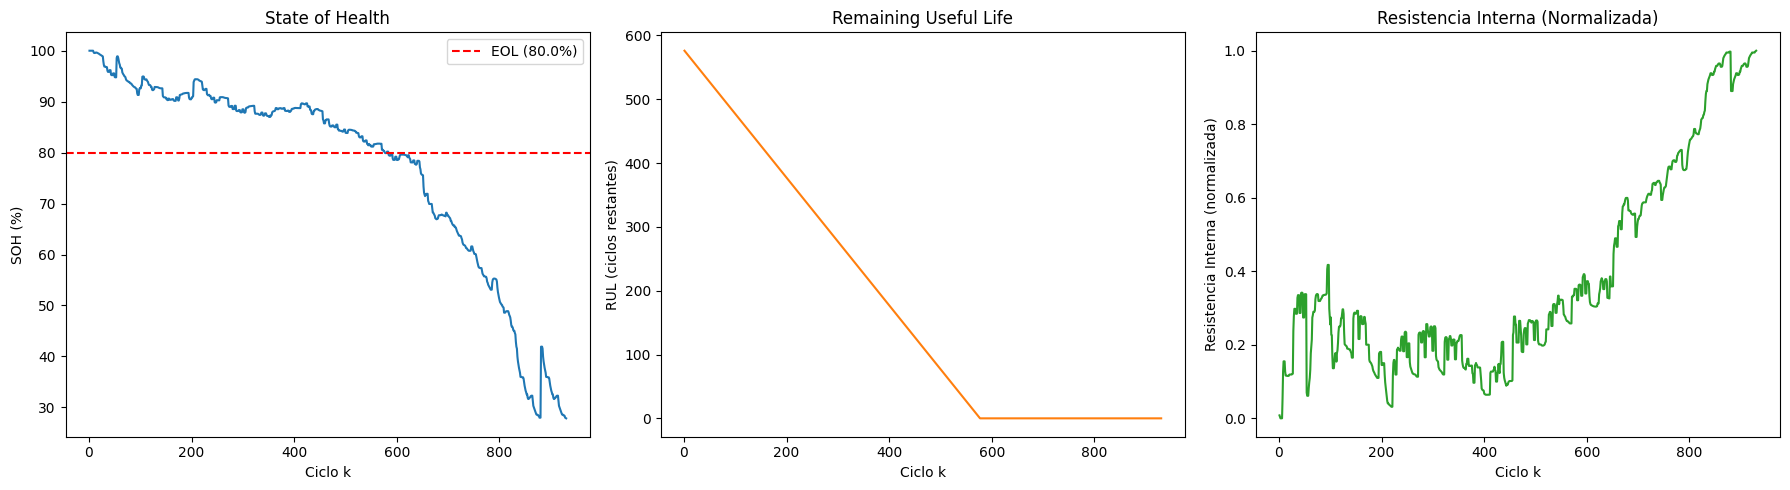

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# SOH vs Ciclo
axes[0].plot(dataset_rna.index + 1, dataset_rna['SOH_%'], color='tab:blue')
axes[0].axhline(y=UMBRAL_EOL_SOH, color='r', linestyle='--', label=f'EOL ({UMBRAL_EOL_SOH}%)')
axes[0].set_xlabel('Ciclo k')
axes[0].set_ylabel('SOH (%)')
axes[0].set_title('State of Health')
axes[0].legend()

# RUL vs Ciclo
axes[1].plot(dataset_rna.index + 1, dataset_rna['RUL_Ciclos'], color='tab:orange')
axes[1].set_xlabel('Ciclo k')
axes[1].set_ylabel('RUL (ciclos restantes)')
axes[1].set_title('Remaining Useful Life')

# Resistencia interna normalizada vs Ciclo
axes[2].plot(dataset_rna.index + 1, dataset_rna['Resistencia_Interna_Ohm_Norm'], color='tab:green')
axes[2].set_xlabel('Ciclo k')
axes[2].set_ylabel('Resistencia Interna (normalizada)')
axes[2].set_title('Resistencia Interna (Normalizada)')

plt.tight_layout()
plt.show()

---
## 5. Partición de los datos

División del dataset normalizado en conjuntos de entrenamiento (80%) y prueba (20%). Se preserva el orden cronológico (sin mezclar aleatoriamente) debido a la naturaleza secuencial de los ciclos de la batería.

In [ ]:
from sklearn.model_selection import train_test_split

# Dividir los datos en 80% entrenamiento y 20% prueba de manera aleatoria (shuffle=True)
train_data, test_data = train_test_split(dataset_rna, test_size=0.2, shuffle=True, random_state=42)

print(f"Total de ciclos: {len(dataset_rna)}")
print(f"Conjunto de entrenamiento (80%): {len(train_data)} ciclos")
print(f"Conjunto de prueba (20%): {len(test_data)} ciclos")

# Guardar las particiones en archivos CSV
PATH_TRAIN = '/content/drive/MyDrive/IA 2C 2026 G12/TP 2/Datos/train_dataset_CS2_35.csv'
PATH_TEST = '/content/drive/MyDrive/IA 2C 2026 G12/TP 2/Datos/test_dataset_CS2_35.csv'

train_data.to_csv(PATH_TRAIN, index=False)
test_data.to_csv(PATH_TEST, index=False)

print(f"\nConjunto de entrenamiento guardado en: {PATH_TRAIN}")
print(f"Conjunto de prueba guardado en: {PATH_TEST}")

Total de ciclos: 930
Conjunto de entrenamiento (80%): 744 ciclos
Conjunto de prueba (20%): 186 ciclos

Conjunto de entrenamiento guardado en: /content/drive/MyDrive/IA 2C 2026 G12/TP 2/Datos/train_dataset_CS2_35.csv
Conjunto de prueba guardado en: /content/drive/MyDrive/IA 2C 2026 G12/TP 2/Datos/test_dataset_CS2_35.csv
